In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install -q scarches faiss-cpu scib-metrics
!pip install --upgrade --force-reinstall git+https://github.com/dpeerlab/SEACells.git --quiet --no-deps
!pip install numpy scipy --upgrade -q
!pip install -q palantir harmonypy statsmodels leidenalg python-igraph
!pip install -q "numpy==1.26.4" "scipy==1.13.1"
!pip install --upgrade --force-reinstall numpy cupy-cuda12x
!pip install "numpy<2.3"
!pip install -q diptest

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 7.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.2/130.2 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 84.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.0/42.0 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 188.8/188.8 kB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 104.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 113.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 76.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 711.2/711.2 kB 54.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.3/102.3 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 102.3 MB/s eta 0:00:00
   ━━

  Using cached numpy-2.2.6-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (62 kB)
Using cached numpy-2.2.6-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (16.5 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.2
    Uninstalling numpy-2.5.2:
      Successfully uninstalled numpy-2.5.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
seacells 0.3.3 requires pyranges, which is not installed.
anndata 0.13.3.post0 requires scipy!=1.17.0,>=1.14, but you have scipy 1.13.1 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.5 which is incompatible.
xarray-einstats 0.11.0 requires scipy>=1.14, but you have scipy 1.13.1 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.5 which is incompatible.
jaxlib 0.11.1 requires scipy>=1.14, but 

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 238.1/238.1 kB 17.6 MB/s eta 0:00:00


**Restart the runtime now** (numpy/scipy/anndata are C-extension linked; an in-process
upgrade won't take effect on already-imported modules), then continue from the next cell.

In [ ]:
_checks = {
    "numpy": "numpy", "scipy": "scipy", "anndata": "anndata", "scanpy": "scanpy",
    "scarches": "scarches", "scvi-tools": "scvi", "seacells": "SEACells",
    "palantir": "palantir", "scib-metrics": "scib_metrics",
    "statsmodels": "statsmodels", "faiss": "faiss", "leidenalg": "leidenalg",
    "diptest": "diptest",
}
_failed = []
for pkg, mod in _checks.items():
    try:
        __import__(mod)
    except ImportError as e:
        _failed.append((pkg, str(e)))
if _failed:
    print("FAILED imports (fix before continuing, then restart runtime again):")
    for pkg, err in _failed:
        print(f"  {pkg}: {err}")
else:
    print("All packages import cleanly.")

All packages import cleanly.


In [ ]:
%run /content/drive/MyDrive/codes/interpretable-prototype/notebooks/nb_setup.py

nb_setup done. Available: get_trainer, run_mc_task, fig_*, LAMBDA_PROTO_UMAP, LAMBDA_PROTO_UMAP_PRECON, LAMBDA_PARAM_UMAP, LAMBDA_RECON_ONLY, train_sure, eval_sure_task1/2/3
Configs: {'LAMBDA_PROTO_UMAP': {'lambda_umap': 1, 'lambda_swav': 0, 'lambda_kl': 0, 'lambda_recon': 0, 'lambda_proto_recon': 0.0, 'umap_similarity': 'proto'}, 'LAMBDA_PARAM_UMAP': {'lambda_umap': 1, 'lambda_swav': 0, 'lambda_kl': 0, 'lambda_recon': 0, 'lambda_proto_recon': 0.0, 'umap_similarity': 'embedding'}, 'LAMBDA_RECON_ONLY': {'lambda_umap': 0, 'lambda_swav': 0, 'lambda_kl': 0, 'lambda_recon': 1, 'lambda_proto_recon': 0.0}}


<Figure size 600x600 with 0 Axes>

In [ ]:
import os
import gc
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import torch

from interpretable_ssl.datasets.dataset_configs import DATASETS
from interpretable_ssl.configs.paths import get_affinity_path
from interpretable_ssl.augmenters.graph_generator import load_or_build_affinity, _ensure_X_ctx
from interpretable_ssl.experiments.tasks import run_mc_task, LAMBDA_PROTO_UMAP_PRECON
from interpretable_ssl.evaluation.collapse_diagnostics import (
    labels_from_trainer, joint_purity_per_metacell, collapse_summary, compare_runs,
    plot_collapse, metacell_sizes, metacell_tightness,
)

# D1 / D2: density-based prototype regularization on s28nsc + BANKSY(lambda=0.8)

**Purpose.** The current `L_nassoc` diagonal measures *containment*
(`edges_inside / volume`), which is additive under merging -- so merging two prototypes
always raises it and hierarchical splits are structurally vetoed. Result: a few huge
metacells plus a tail of near-empty ones. This notebook tests two independent fixes,
**added one at a time**:

| run | `nassoc_diag_norm` | `nassoc_diag_loss` | `nassoc_gamma` | expected outcome |
|---|---|---|---|---|
| A baseline | `volume` | `mse` | -- | **collapses to giants** = the merge bias |
| B D1 only | **`pair`** | `mse` | -- | **fragments to tiny metacells** |
| C D1+D2 | **`pair`** | **`cpm`** | **swept** | optimum lands in between |

**Run B is expected to look bad, and that is the point.** On a kNN graph
`density <= k/(size-1)`, so a target of 1 is unreachable and `pair`+`mse` is minimized by
metacells of size 2. B fragmenting is direct evidence that swapping the denominator
flipped the preference from "always merge" to "always split" -- i.e. that D1 does what it
claims. `gamma` in run C is then what places the optimum between the two extremes.
`cpm` rather than `hinge` for C: `hinge` goes silent above `gamma` (no gradient), so it
only lifts the veto on splits; `cpm` keeps a gradient and its `pairs` weighting is what
makes a big loose prototype dominate the loss and actively prefer a split. `cpm` gives
empty prototypes zero weight, so `lambda_proto_usage` (already 0.1 in the base config)
must stay on to refill dead slots.

**Everything else is held identical to the existing rebuttal baseline**
(`ctx_pca_product_experiment.ipynb`): same dataset, same affinity (`bk08`), same
`cvae_epochs=50 / train_epochs=15`, same `num_prototypes`, same `LAMBDA_PROTO_UMAP_PRECON`.

**Read before running.**
- Run A **loads** an existing checkpoint; it never retrains. If the load fails, stop and
  fix the path rather than training a fresh "baseline" that isn't the one we reported.
- `gamma`'s absolute scale is arbitrary (it depends on the affinity scale and the
  minibatch sampling rate), so `GAMMAS` is a log sweep. Read off the resulting mean
  metacell size rather than trusting any single value.
- Cells are ordered so a Colab disconnect loses one run, not the notebook.

In [ ]:
# ---------------------------- CONFIG ----------------------------
DS_ID = 's28nsc'
CT_KEY = 'celltypes'
NICHE_KEY = 'niches_2D'
AFFINITY_TYPE = 'bk08'          # pybanksy, lambda=0.8, num_neighbours=32, n_components=50
K_GRAPH = 50
N_PROTOTYPES = 200              # matches ctx_pca_product_experiment.ipynb's bk08 runs

# held identical across A/B/C
BASE_KW = dict(
    cvae_epochs=50, train_epochs=15, eval_freq=5, patience=10,
    batch_size=1024, affinity_type=AFFINITY_TYPE, num_prototypes=N_PROTOTYPES,
    label_key=CT_KEY, niche_key=NICHE_KEY, skip_metrics=['task2', 'task3'],
)
BASELINE_EXP = 'proto_bk08_np200_ema15'       # the ALREADY-TRAINED run to load

GAMMAS = [0.01, 0.03, 0.1]      # D2 sweep; log-spaced, refine after seeing mean size
SKIP_IF_EXISTS = True

OUT_DIR = '/content/drive/MyDrive/codes/interpretable-prototype/files/tables/d1_d2_s28nsc_bk08'
FIG_DIR = '/content/drive/MyDrive/codes/interpretable-prototype/files/figures/d1_d2_s28nsc_bk08'
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

summaries = {}      # run name -> summary row
labels_by_run = {}  # run name -> per-cell metacell id

In [ ]:
# ---- CLAUDE.md section 9 check: confirm the new options actually reach the model name ----
# A missing ABBREVIATIONS entry is silently dropped, which would make two different runs
# share one model folder and clobber each other's checkpoints. Verify BEFORE training.
from interpretable_ssl.configs.defaults import get_defaults
from interpretable_ssl.constants import ABBREVIATIONS

_d = get_defaults()
for _k, _expect_default in [('nassoc_diag_norm', 'volume'), ('nassoc_gamma', 0.0),
                            ('nassoc_diag_loss', 'mse')]:
    assert _k in ABBREVIATIONS, f'{_k} missing from ABBREVIATIONS -> would be silently dropped'
    assert _d[_k] == _expect_default, f'{_k} default changed: {_d[_k]!r} != {_expect_default!r}'
print('config keys OK:', {k: ABBREVIATIONS[k] for k in
                          ['nassoc_diag_norm', 'nassoc_gamma', 'nassoc_diag_loss']})
# 4-char truncation rule: string values must differ within their first 4 chars
assert len({v[:4] for v in ['volume', 'pair']}) == 2
assert len({v[:4] for v in ['mse', 'nll', 'nll2', 'hinge', 'cpm']}) == 5
print('4-char truncation OK')

config keys OK: {'nassoc_diag_norm': 'nadn', 'nassoc_gamma': 'nagm', 'nassoc_diag_loss': 'nadl'}
4-char truncation OK


In [ ]:
ds_conf = DATASETS[DS_ID]
adata = sc.read_h5ad(ds_conf['path'])
_ensure_X_ctx(adata)
print(adata)
print('\ncell types:\n', adata.obs[CT_KEY].value_counts())
print('\nniches:\n', adata.obs[NICHE_KEY].value_counts(dropna=False))

[X_ctx] using existing X_ctx already in adata (not recomputed)
AnnData object with n_obs × n_vars = 58423 × 960
    obs: 'section', 'celltypes', 'niches_3D', 'niches_2D', 'fibroblast_subclusters', 'tumor_pseudotime_rank', 'EMT_niche'
    uns: 'EMT_niche_colors', 'celltypes_colors', 'fibroblast_subclusters_colors', 'log1p', 'niches_2D_colors', 'niches_3D_colors', 'pca'
    obsm: 'X_covet', 'X_ctx', 'X_pca', 'X_umap_2D_neighbourhoods', 'X_umap_3D_neighbourhoods', 'X_umap_SCT', 'spatial'
    varm: 'PCs'
    layers: 'SCT', 'counts', None (.X)

cell types:
 celltypes
Fibroblasts                    15309
Tumor cells                    11382
Macrophages                     9390
Cytotoxic T cells               6011
Respiratory epithelium          2255
Vascular endothelium            2051
Monocytes                       1920
Plasma cells                    1637
Pericytes                       1483
Smooth muscle cells             1389
Regulatory T cells              1100
Cycling immune cells    

In [ ]:
# The SAME affinity object every run trains against and every diagnostic is computed on.
affinity = load_or_build_affinity(
    adata, DS_ID, affinity_type=AFFINITY_TYPE, k=K_GRAPH, k_neighbors=K_GRAPH,
    bk=ds_conf.get('batch_key'))
print('affinity:', affinity.shape, 'nnz =', affinity.nnz if hasattr(affinity, 'nnz') else 'dense')

[load_or_build_affinity] found cached graph at ./graphs/affinity_s28nsc58423_ncomp50_kneighbors50_bk08.pkl -- loading (not recomputing)
affinity: (58423, 58423) nnz = 4058285


## Run A -- baseline (load only, never retrain)

In [ ]:
tA, _, _ = run_mc_task(
    DS_ID, **{**BASE_KW, 'train_epochs': 1, 'eval_freq': 1, 'patience': 1},
    lambda_config=dict(LAMBDA_PROTO_UMAP_PRECON),
    trainer_kwargs={'experiment_name': BASELINE_EXP},
    load_umap=True, skip_eval=True,
)
print('loaded baseline:', tA.get_model_name())
labels_by_run['A_baseline'] = labels_from_trainer(tA, adata)

dataset is None, loading s28nsc
loading s28nsc data
⚠️ No HVG column found.
proto_bk08_np200_ema15_ds-s28n_NP200_prtInit-wayp_aff-bk08_lprec0.01_usim-prot_cvae_e50_ecal1_lpu0.1_pum-ema_lna1_nagg-max_upm-dotp_v31
Embedding dictionary:
 	Num conditions: [1]
 	Embedding dim: [10]
Encoder Architecture:
	Input Layer in, out and cond: 960 31 10
	Mean/Var Layer in/out: 31 8
Decoder Architecture:
	First Layer in, out and cond:  8 31 10
	Output Layer in/out:  31 960 

📊 Affinity: wdeg[min/mean/max]=11.385/24.968/163.001, effk_med=59.0, mutual=100.00%
adam
Loaded pretrain checkpoint from /content/drive/MyDrive/models/s28nsc/pretrain/pretrain_ds-s28nsc_cvae_e50_NP200/pretrain_checkpoint.pth
  pretrain_params: {'dataset_id': 's28nsc', 'cvae_epochs': 50, 'batch_size': 1024, 'latent_dims': 8, 'l2norm': 1, 'model_type': 'gm', 'beta': 0.3, 'num_prototypes': 200, 'condition_key': 'section'}
📊 EdgeDataset: 3999862 edges
   Weight range: [0.0134, 0.9911]
   umap_steps_per_epoch=1000 → 1024000 edges/epoch

  0%|          | 0/58 [00:00<?, ?it/s]

In [ ]:
_lab = labels_by_run['A_baseline']
_pur = joint_purity_per_metacell(_lab, adata, CT_KEY, NICHE_KEY)
summaries['A_baseline'] = collapse_summary(_lab, affinity=affinity, name='A_baseline', purity=_pur)
pd.Series(summaries['A_baseline']).to_frame('A_baseline')

,A_baseline
run,A_baseline
largest_share,0.153518
dip_stat,0.0825
dip_p,0.0
tightness_gap,0.057042
size_tightness_corr,0.085364
purity_micro,0.31289
purity_gap,0.307147


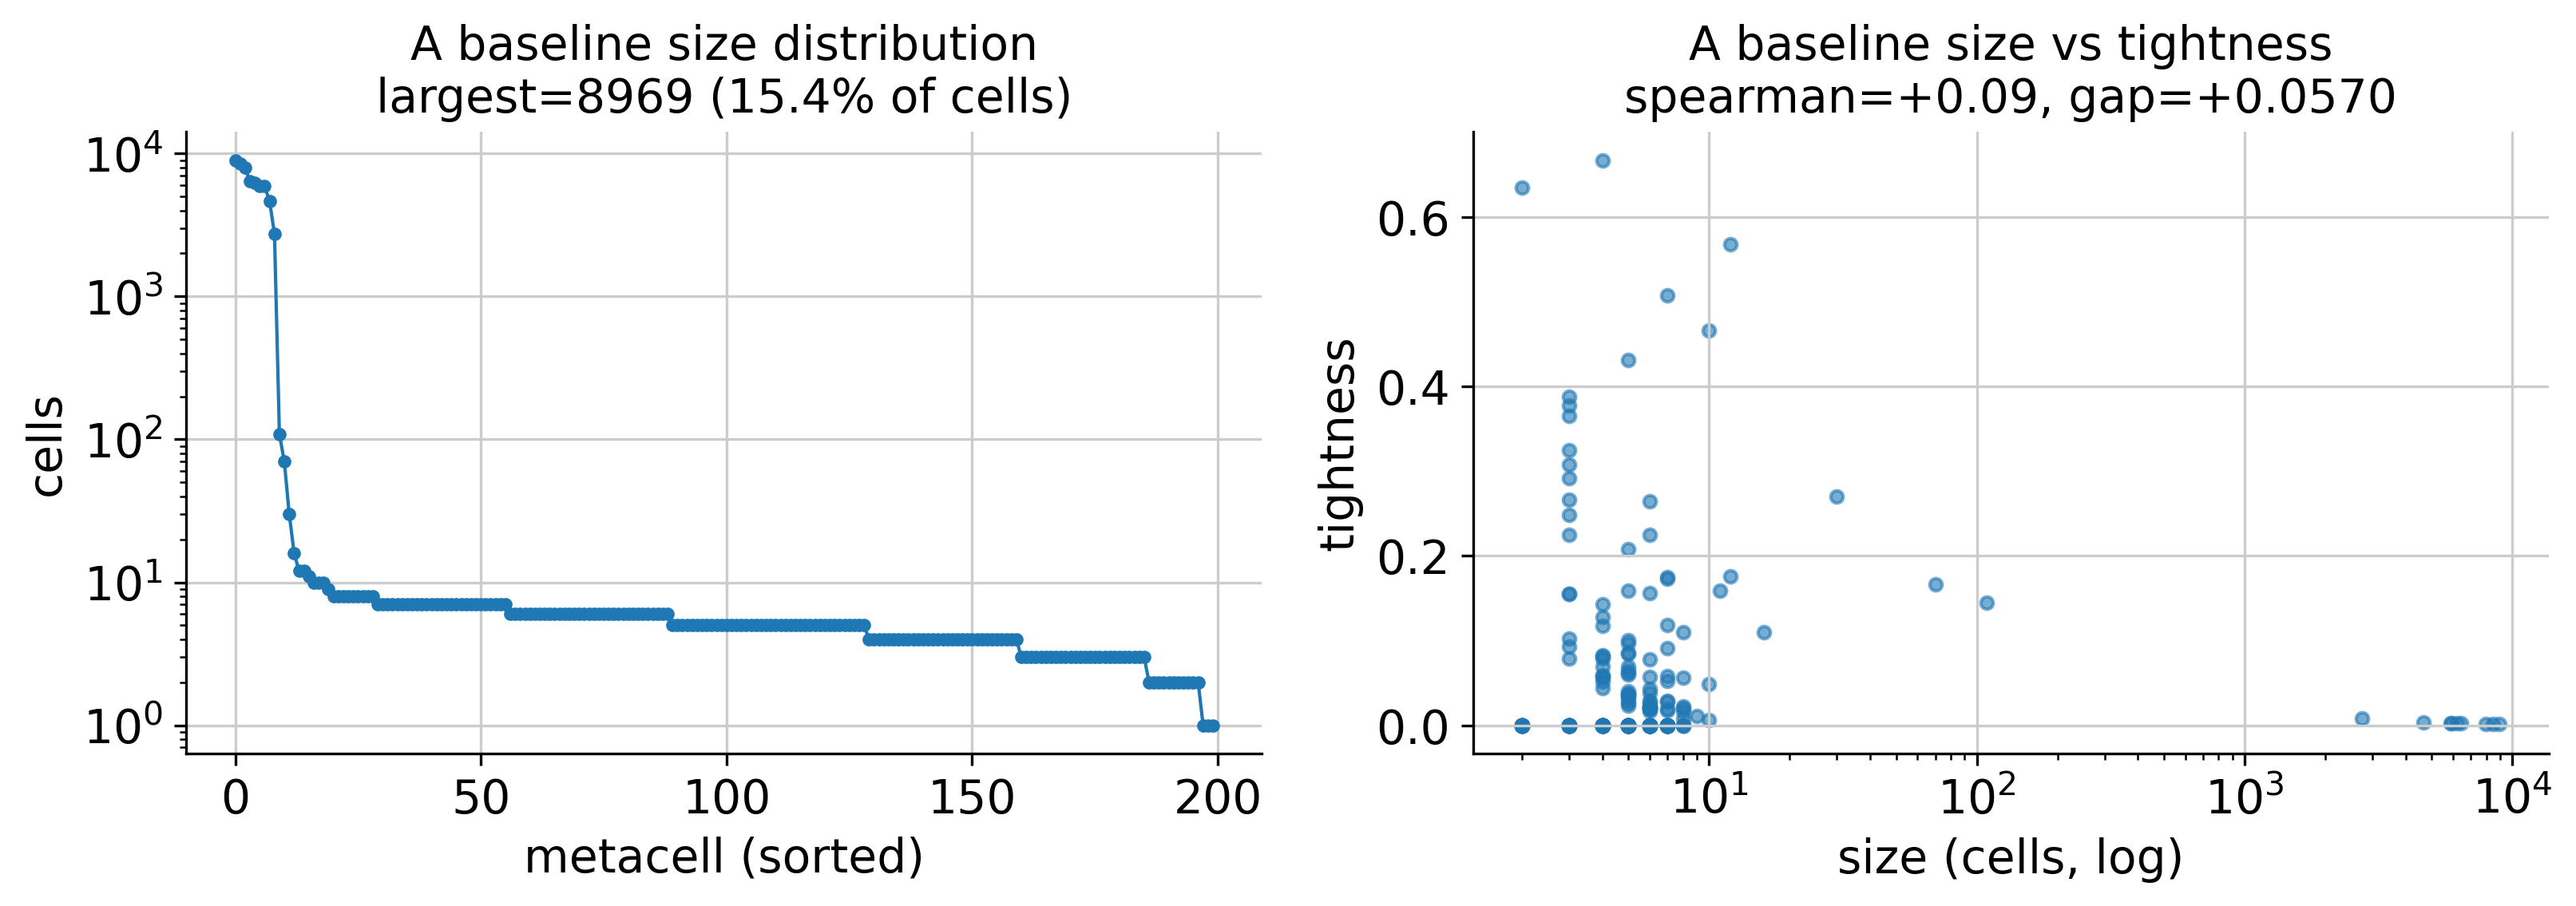

In [ ]:
plot_collapse(_lab, affinity, name='A baseline')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/A_baseline.png', dpi=120, bbox_inches='tight')
plt.show()

## Baseline diagnosis, part 2 -- SEACells on the same graph

**Nothing has trained yet.** Run A and this section only LOAD saved models, so by the end
of this cell you can already see -- for scProto's current loss AND for both SEACells
variants (bk08 and PCA) -- whether the collapse exists, on the same affinity and the same
metrics. Only if it does is there any reason to run B/C/D.

SEACells is not a competitor here: it picks archetypes rather than optimizing a
containment objective, so it is the reference for what a healthy size/tightness
distribution looks like on this exact graph.

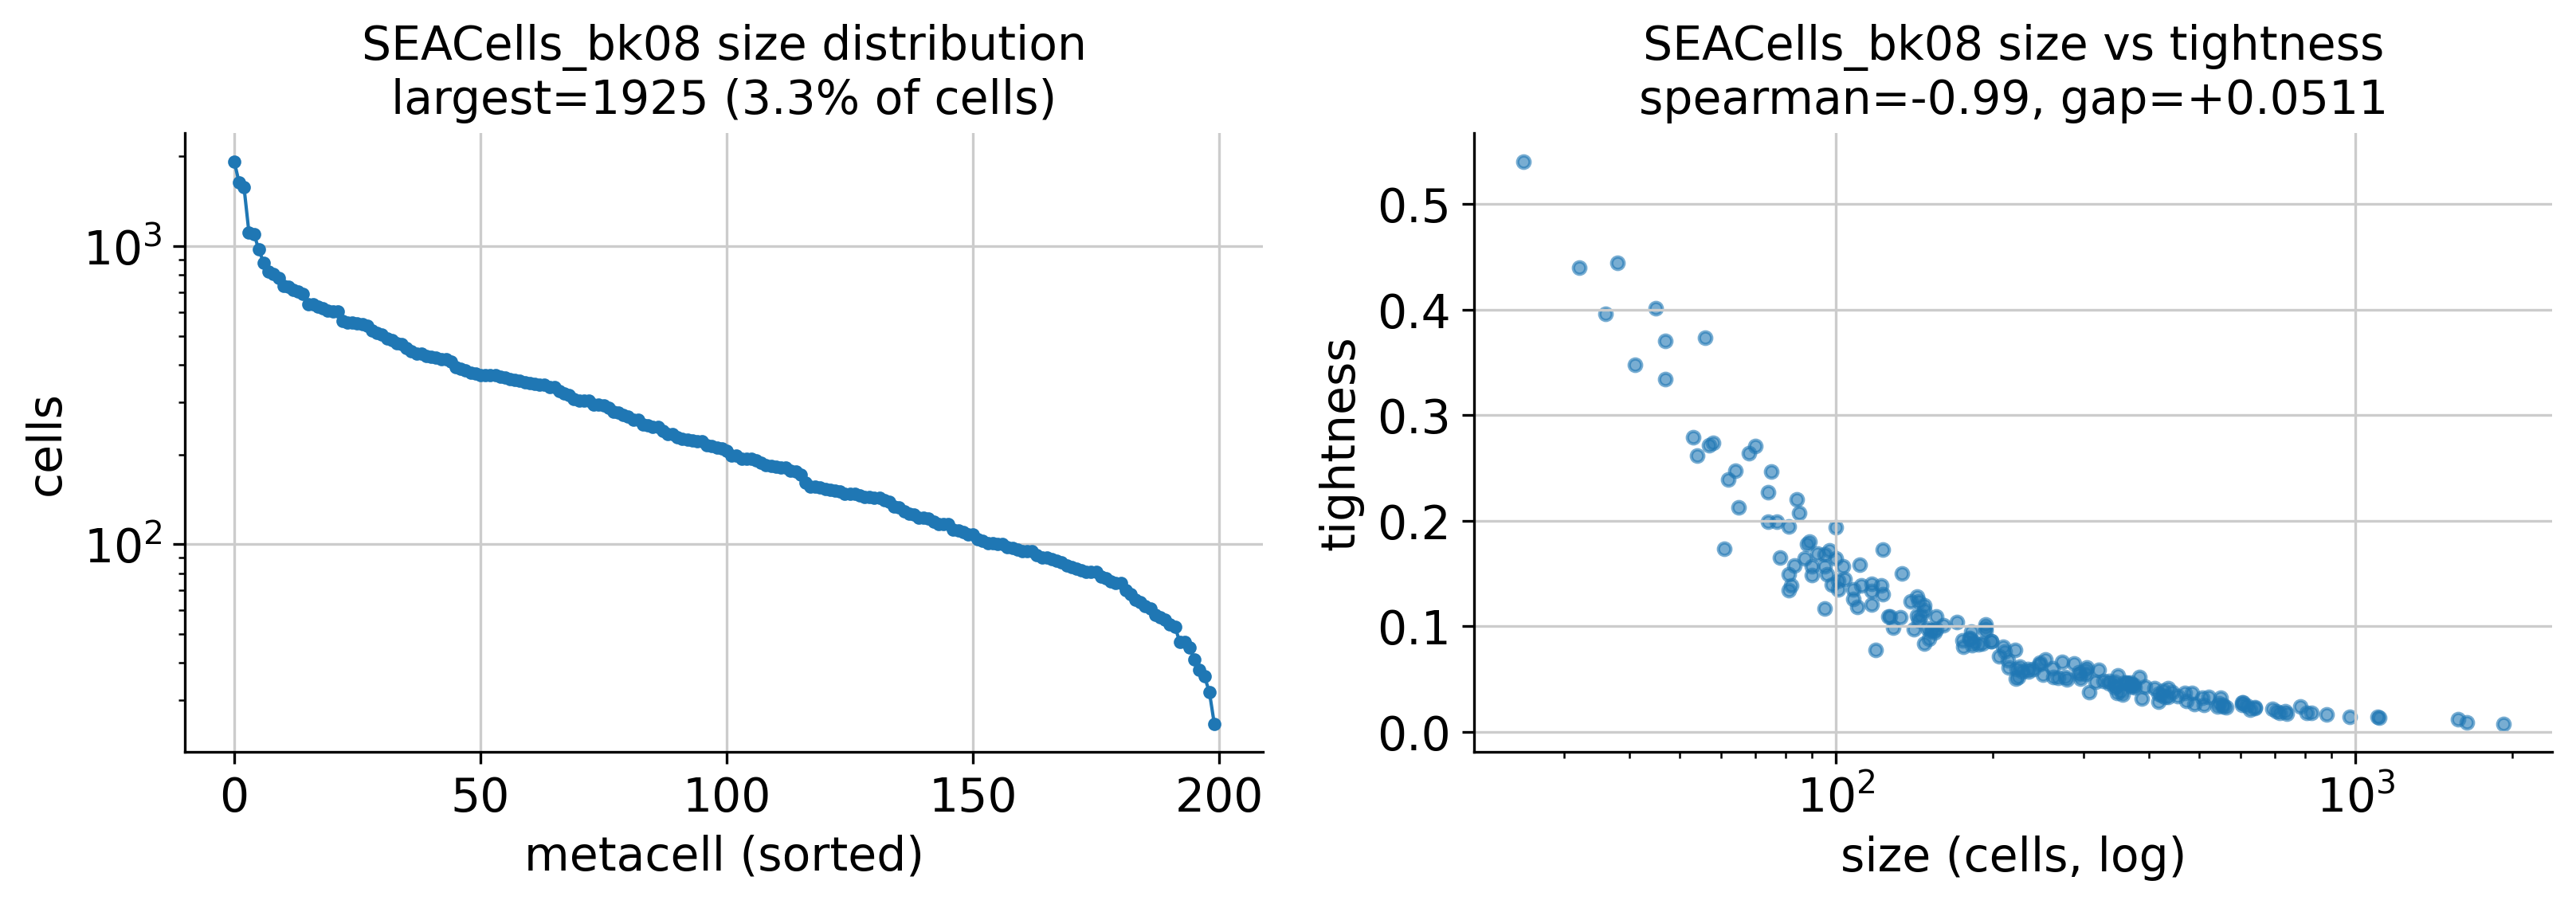

skip SEACells_pca: no saved run (TypeError: expected str, bytes or os.PathLike object, not NoneType)


In [ ]:
# READ-ONLY: loads SEACells runs already on disk (cell_assignments.csv). It never trains,
# so it cannot cost a Colab session. If a tag isn't there yet, it is skipped -- train it in
# the notebook that owns it (seacells_train.ipynb / ctx_pca_product_experiment.ipynb)
# rather than here.
from interpretable_ssl.evaluation.paper_figures import _resolve_run_dir
from interpretable_ssl.evaluation.niche_program_recovery import load_cell_assignments

for sc_name, sc_tag in [('SEACells_bk08', AFFINITY_TYPE), ('SEACells_pca', 'X_pca')]:
    try:
        run_dir = _resolve_run_dir(DS_ID, f'seacell_{sc_tag}')
        lab = load_cell_assignments(run_dir, adata, NICHE_KEY)['metacell_id']
    except Exception as e:
        print(f'skip {sc_name}: no saved run ({type(e).__name__}: {e})')
        continue
    # tightness is computed against `affinity`, whose rows follow adata's cell order --
    # so the label vector MUST be reindexed to adata.obs_names, not left in csv order.
    lab = lab.reindex(adata.obs_names.to_numpy())
    if lab.isna().any():
        print(f'{sc_name}: {int(lab.isna().sum())} cells unassigned in the saved run; '
              f'they are excluded from its metacells but still count in the graph.')
    labels_by_run[sc_name] = lab
    pur = joint_purity_per_metacell(lab, adata, CT_KEY, NICHE_KEY)
    summaries[sc_name] = collapse_summary(lab, affinity=affinity, name=sc_name, purity=pur)
    plot_collapse(lab, affinity, name=sc_name)
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/{sc_name}.png', dpi=120, bbox_inches='tight')
    plt.show()

## Run B -- D1 only (density denominator, nothing else changed)

In [ ]:
lcB = dict(LAMBDA_PROTO_UMAP_PRECON)
lcB['nassoc_diag_norm'] = 'pair'          # <-- D1. The ONLY change vs run A.
expB = 'proto_bk08_np200_ema15_d1pair'

try:
    if not SKIP_IF_EXISTS:
        raise FileNotFoundError
    tB, _, _ = run_mc_task(
        DS_ID, **{**BASE_KW, 'train_epochs': 1, 'eval_freq': 1, 'patience': 1},
        lambda_config=lcB, trainer_kwargs={'experiment_name': expB},
        load_umap=True, skip_eval=True)
    print('loaded existing D1 run')
except FileNotFoundError:
    print('=== training D1 (nassoc_diag_norm=pair) ===')
    tB, _, _ = run_mc_task(DS_ID, **BASE_KW, lambda_config=lcB,
                           trainer_kwargs={'experiment_name': expB})
print('model name:', tB.get_model_name())
labels_by_run['B_d1_pair'] = labels_from_trainer(tB, adata)

dataset is None, loading s28nsc
loading s28nsc data
⚠️ No HVG column found.
proto_bk08_np200_ema15_d1pair_ds-s28n_NP200_prtInit-wayp_aff-bk08_lprec0.01_usim-prot_cvae_e50_ecal1_lpu0.1_pum-ema_lna1_nagg-max_nadn-pair_upm-dotp_v31
Embedding dictionary:
 	Num conditions: [1]
 	Embedding dim: [10]
Encoder Architecture:
	Input Layer in, out and cond: 960 31 10
	Mean/Var Layer in/out: 31 8
Decoder Architecture:
	First Layer in, out and cond:  8 31 10
	Output Layer in/out:  31 960 

📊 Affinity: wdeg[min/mean/max]=11.385/24.968/163.001, effk_med=59.0, mutual=100.00%
adam
Loaded pretrain checkpoint from /content/drive/MyDrive/models/s28nsc/pretrain/pretrain_ds-s28nsc_cvae_e50_NP200/pretrain_checkpoint.pth
  pretrain_params: {'dataset_id': 's28nsc', 'cvae_epochs': 50, 'batch_size': 1024, 'latent_dims': 8, 'l2norm': 1, 'model_type': 'gm', 'beta': 0.3, 'num_prototypes': 200, 'condition_key': 'section'}
📊 EdgeDataset: 3999862 edges
   Weight range: [0.0134, 0.9911]
   umap_steps_per_epoch=1000 → 10

  0%|          | 0/58 [00:00<?, ?it/s]

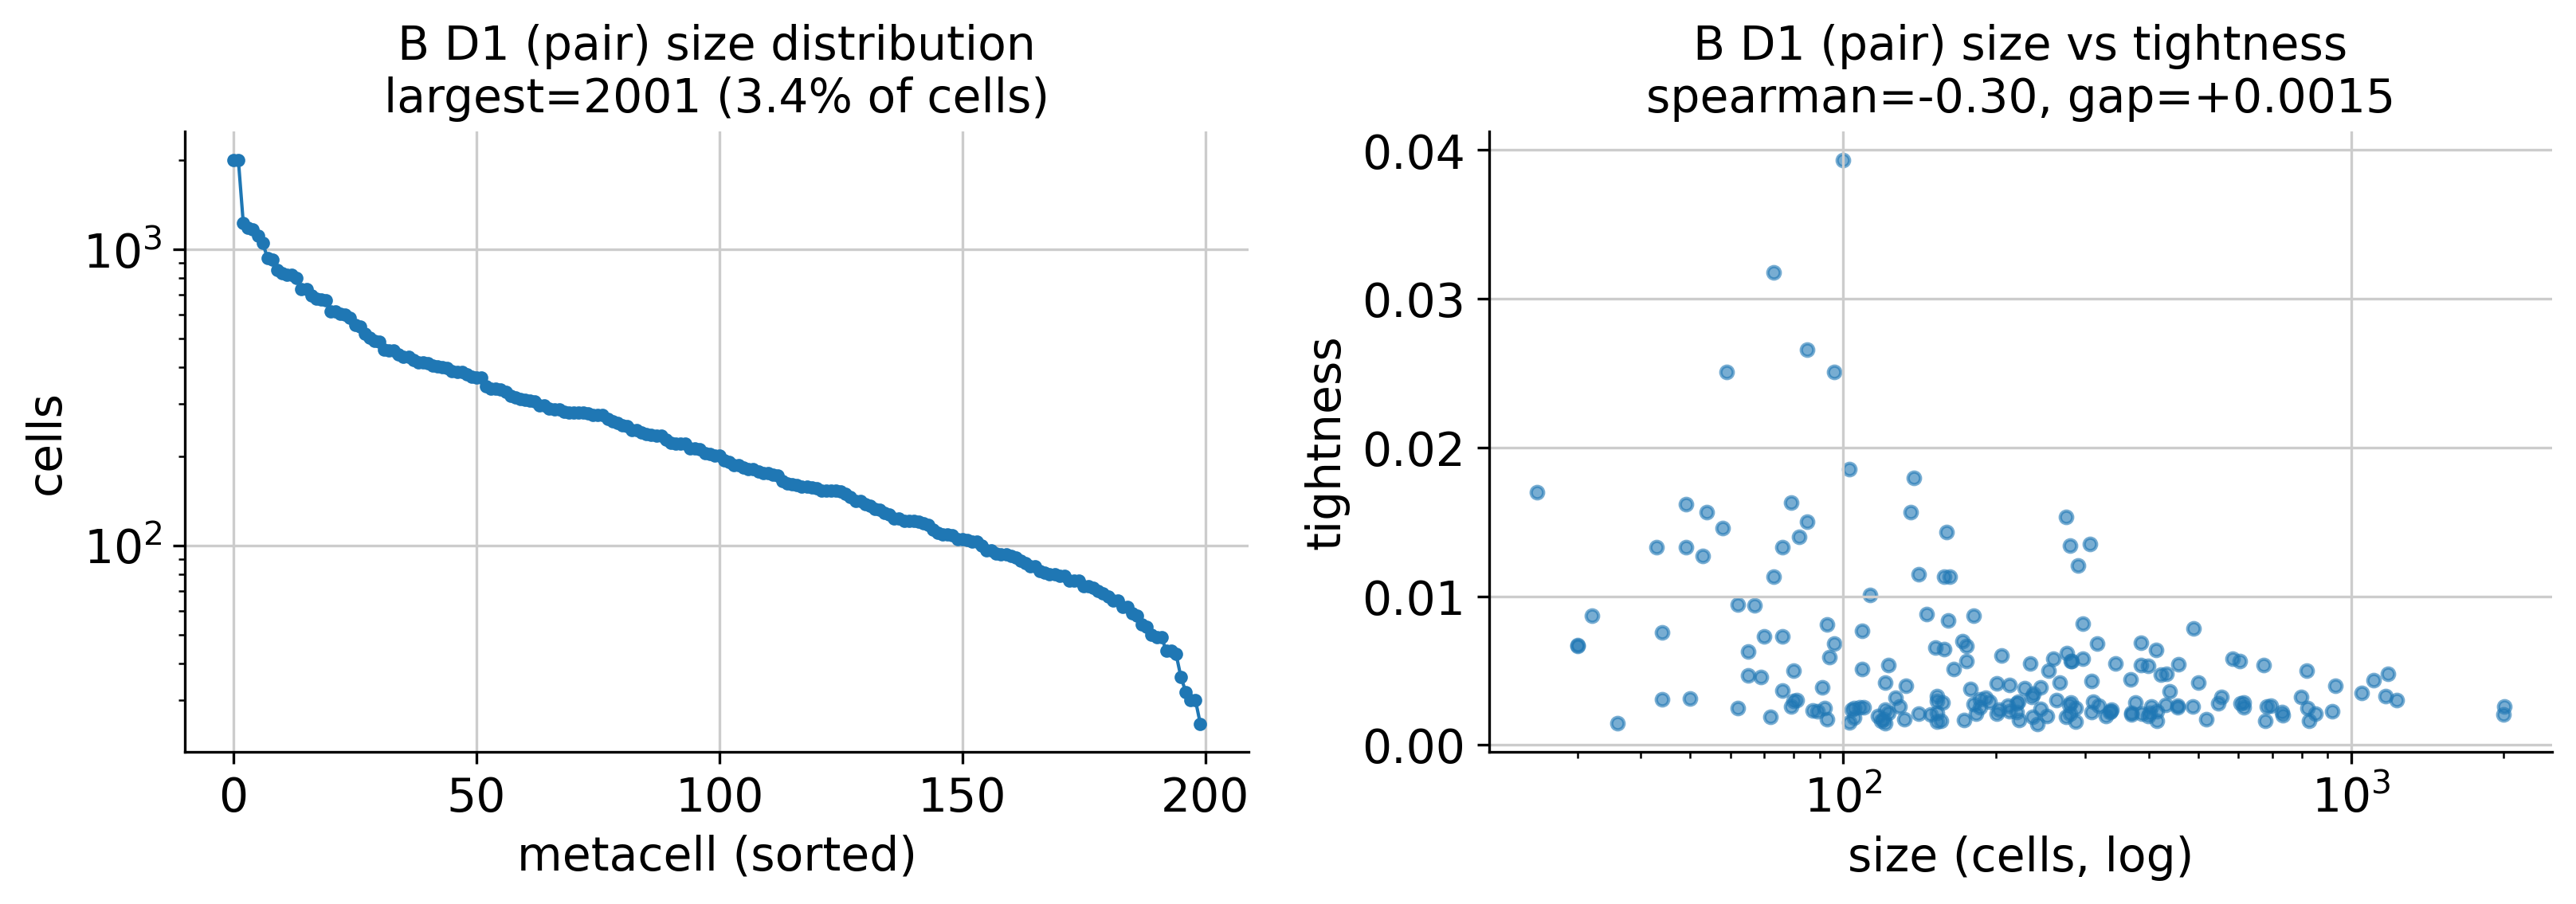

run,A_baseline,B_d1_pair
largest_share,0.153518,0.034250
dip_stat,0.082500,0.016835
dip_p,0.000000,0.985597
tightness_gap,0.057042,0.001461
size_tightness_corr,0.085364,-0.301877
purity_micro,0.312890,0.353508
purity_gap,0.307147,-0.009013


In [ ]:
_lab = labels_by_run['B_d1_pair']
_pur = joint_purity_per_metacell(_lab, adata, CT_KEY, NICHE_KEY)
summaries['B_d1_pair'] = collapse_summary(_lab, affinity=affinity, name='B_d1_pair', purity=_pur)
plot_collapse(_lab, affinity, name='B D1 (pair)')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/B_d1_pair.png', dpi=120, bbox_inches='tight')
plt.show()
pd.DataFrame([summaries['A_baseline'], summaries['B_d1_pair']]).set_index('run').T

In [ ]:
del tB; gc.collect(); torch.cuda.empty_cache()

## Run C -- D1 + D2 (density + CPM resolution knob), one gamma at a time

dataset is None, loading s28nsc
loading s28nsc data
⚠️ No HVG column found.
proto_bk08_np200_ema15_d1d2_g0.01_ds-s28n_NP200_prtInit-wayp_aff-bk08_lprec0.01_usim-prot_cvae_e50_ecal1_lpu0.1_pum-ema_lna1_nagg-max_nadl-cpm_nadn-pair_nagm0.01_upm-dotp_v31
Embedding dictionary:
 	Num conditions: [1]
 	Embedding dim: [10]
Encoder Architecture:
	Input Layer in, out and cond: 960 31 10
	Mean/Var Layer in/out: 31 8
Decoder Architecture:
	First Layer in, out and cond:  8 31 10
	Output Layer in/out:  31 960 

📊 Affinity: wdeg[min/mean/max]=11.385/24.968/163.001, effk_med=59.0, mutual=100.00%
adam
=== training D1+D2, gamma=0.01 ===
dataset is None, loading s28nsc
loading s28nsc data
⚠️ No HVG column found.
proto_bk08_np200_ema15_d1d2_g0.01_ds-s28n_NP200_prtInit-wayp_aff-bk08_lprec0.01_usim-prot_cvae_e50_ecal1_lpu0.1_pum-ema_lna1_nagg-max_nadl-cpm_nadn-pair_nagm0.01_upm-dotp_v31
Embedding dictionary:
 	Num conditions: [1]
 	Embedding dim: [10]
Encoder Architecture:
	Input Layer in, out and cond: 960

waypoint MaxMin: 100%|██████████| 199/199 [00:00<00:00, 794.67proto/s]


[waypoint init] selected 200 seed cells


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/58 [00:00<?, ?it/s]

...

Saved metacells (200 prototypes) to /content/drive/MyDrive/models//s28nsc/proto_bk08_np200_ema15_d1d2_g0.01_ds-s28n_NP200_prtInit-wayp_aff-bk08_lprec0.01_usim-prot_cvae_e50_ecal1_lpu0.1_pum-ema_lna1_nagg-max_nadl-cpm_nadn-pair_nagm0.01_upm-dotp_v31/metacells.h5ad


  0%|          | 0/49 [00:00<?, ?it/s]

  0%|          | 0/58 [00:00<?, ?it/s]

UMAP data saved to /content/drive/MyDrive/models//s28nsc/proto_bk08_np200_ema15_d1d2_g0.01_ds-s28n_NP200_prtInit-wayp_aff-bk08_lprec0.01_usim-prot_cvae_e50_ecal1_lpu0.1_pum-ema_lna1_nagg-max_nadl-cpm_nadn-pair_nagm0.01_upm-dotp_v31
model name: proto_bk08_np200_ema15_d1d2_g0.01_ds-s28n_NP200_prtInit-wayp_aff-bk08_lprec0.01_usim-prot_cvae_e50_ecal1_lpu0.1_pum-ema_lna1_nagg-max_nadl-cpm_nadn-pair_nagm0.01_upm-dotp_v31


  0%|          | 0/58 [00:00<?, ?it/s]

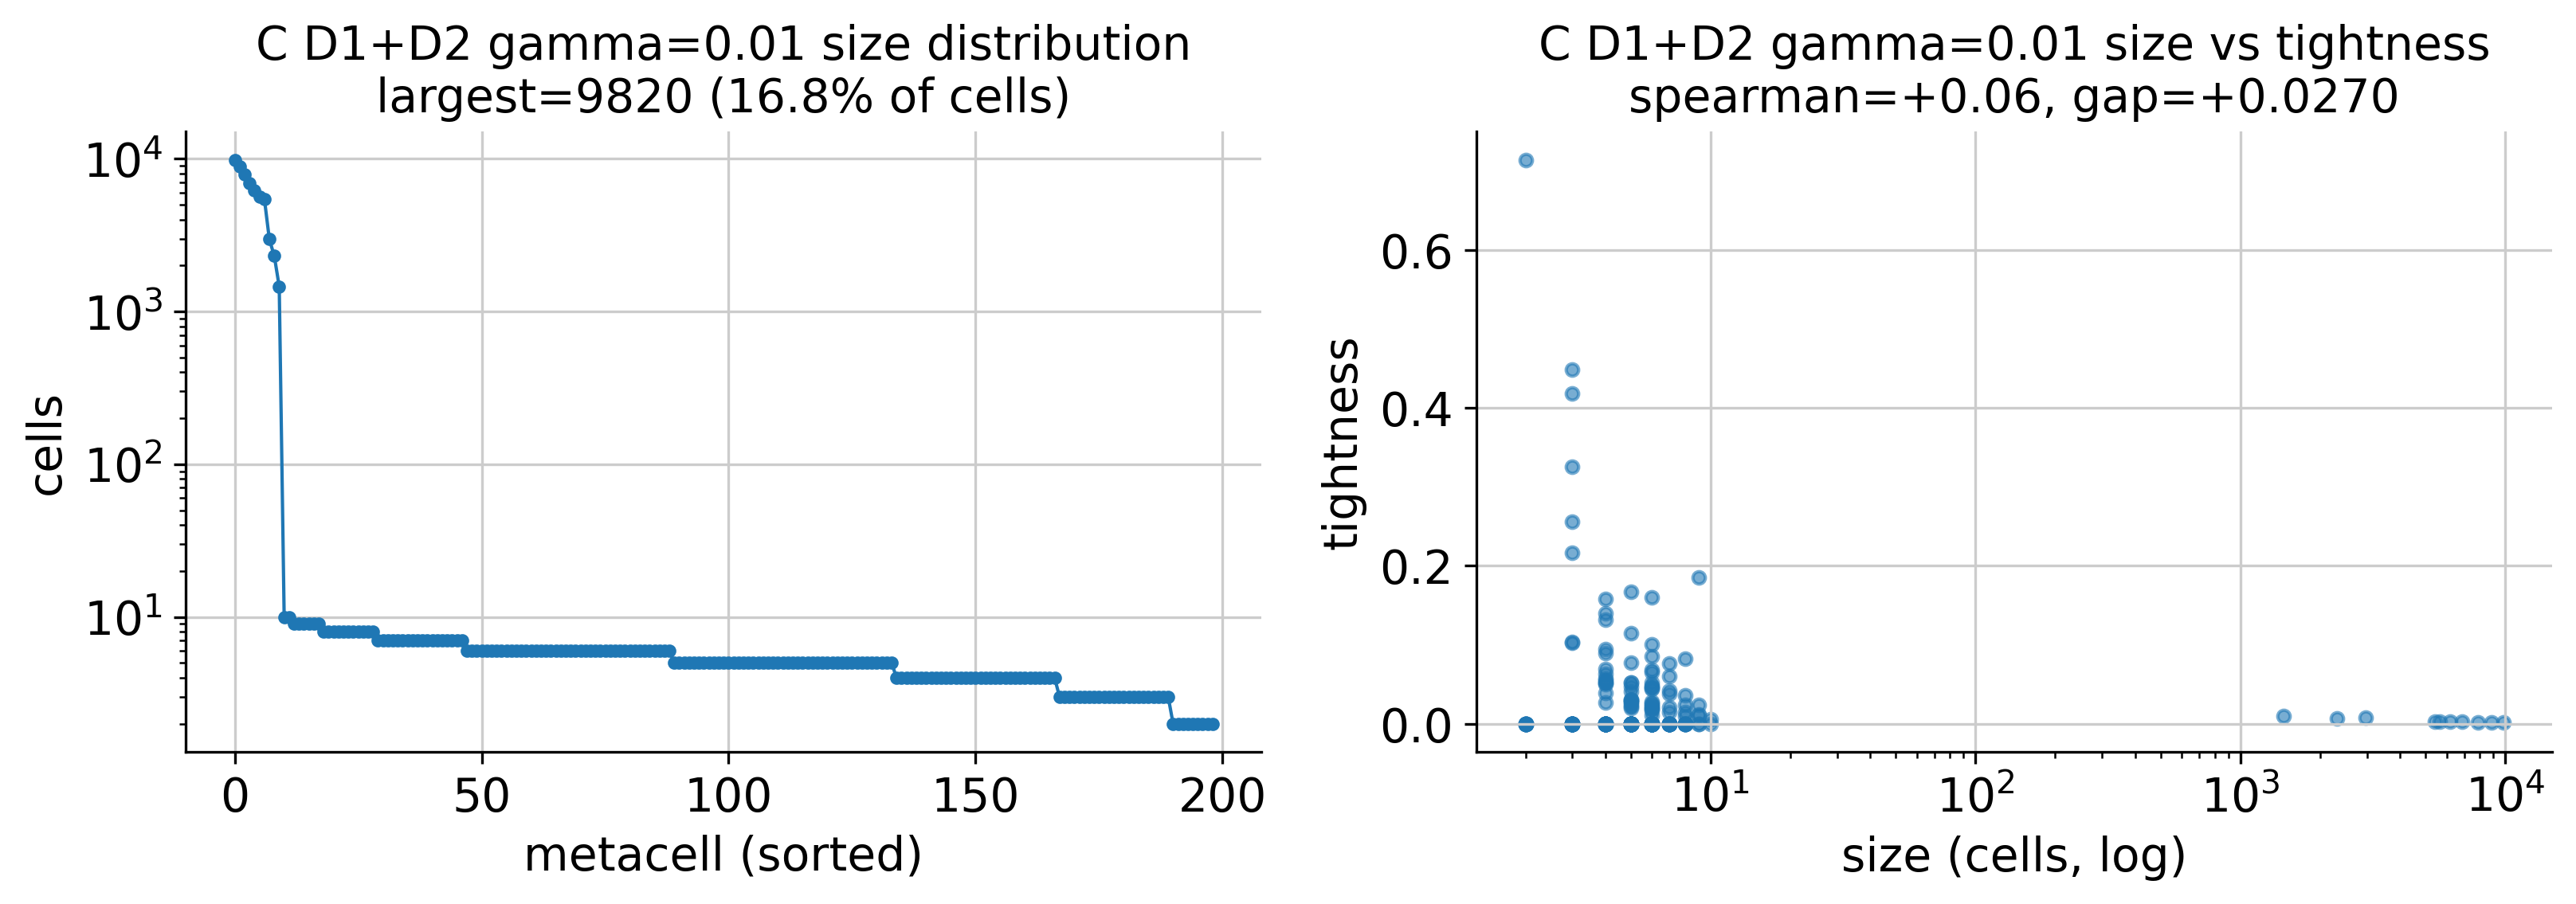

dataset is None, loading s28nsc
loading s28nsc data
⚠️ No HVG column found.
proto_bk08_np200_ema15_d1d2_g0.03_ds-s28n_NP200_prtInit-wayp_aff-bk08_lprec0.01_usim-prot_cvae_e50_ecal1_lpu0.1_pum-ema_lna1_nagg-max_nadl-cpm_nadn-pair_nagm0.03_upm-dotp_v31
Embedding dictionary:
 	Num conditions: [1]
 	Embedding dim: [10]
Encoder Architecture:
	Input Layer in, out and cond: 960 31 10
	Mean/Var Layer in/out: 31 8
Decoder Architecture:
	First Layer in, out and cond:  8 31 10
	Output Layer in/out:  31 960 

📊 Affinity: wdeg[min/mean/max]=11.385/24.968/163.001, effk_med=59.0, mutual=100.00%
adam
=== training D1+D2, gamma=0.03 ===
dataset is None, loading s28nsc
loading s28nsc data
⚠️ No HVG column found.
proto_bk08_np200_ema15_d1d2_g0.03_ds-s28n_NP200_prtInit-wayp_aff-bk08_lprec0.01_usim-prot_cvae_e50_ecal1_lpu0.1_pum-ema_lna1_nagg-max_nadl-cpm_nadn-pair_nagm0.03_upm-dotp_v31
Embedding dictionary:
 	Num conditions: [1]
 	Embedding dim: [10]
Encoder Architecture:
	Input Layer in, out and cond: 960

waypoint MaxMin: 100%|██████████| 199/199 [00:00<00:00, 730.65proto/s]


[waypoint init] selected 200 seed cells


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/58 [00:00<?, ?it/s]

...

Saved metacells (200 prototypes) to /content/drive/MyDrive/models//s28nsc/proto_bk08_np200_ema15_d1d2_g0.03_ds-s28n_NP200_prtInit-wayp_aff-bk08_lprec0.01_usim-prot_cvae_e50_ecal1_lpu0.1_pum-ema_lna1_nagg-max_nadl-cpm_nadn-pair_nagm0.03_upm-dotp_v31/metacells.h5ad


  0%|          | 0/49 [00:00<?, ?it/s]

  0%|          | 0/58 [00:00<?, ?it/s]

UMAP data saved to /content/drive/MyDrive/models//s28nsc/proto_bk08_np200_ema15_d1d2_g0.03_ds-s28n_NP200_prtInit-wayp_aff-bk08_lprec0.01_usim-prot_cvae_e50_ecal1_lpu0.1_pum-ema_lna1_nagg-max_nadl-cpm_nadn-pair_nagm0.03_upm-dotp_v31
model name: proto_bk08_np200_ema15_d1d2_g0.03_ds-s28n_NP200_prtInit-wayp_aff-bk08_lprec0.01_usim-prot_cvae_e50_ecal1_lpu0.1_pum-ema_lna1_nagg-max_nadl-cpm_nadn-pair_nagm0.03_upm-dotp_v31


  0%|          | 0/58 [00:00<?, ?it/s]

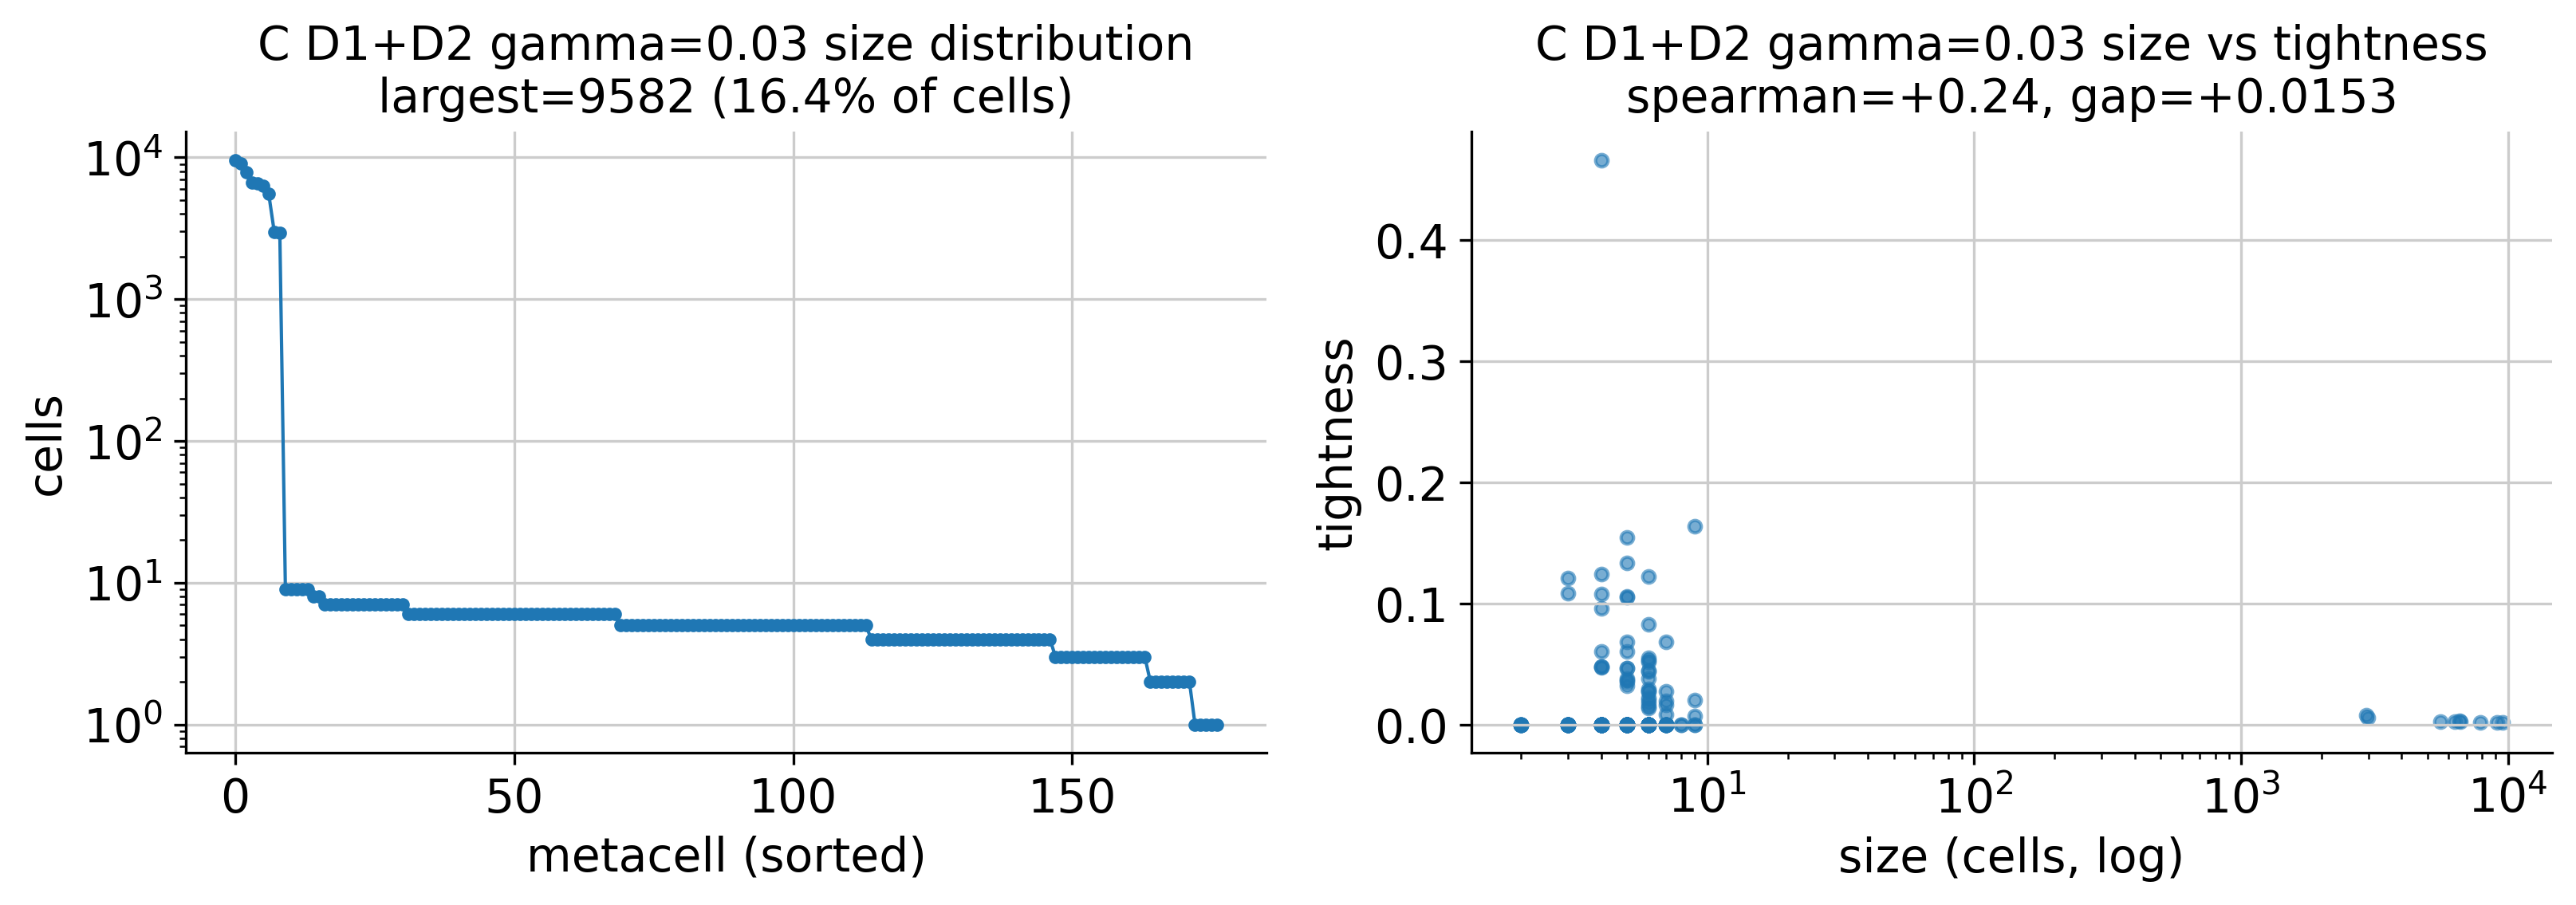

dataset is None, loading s28nsc
loading s28nsc data
⚠️ No HVG column found.
proto_bk08_np200_ema15_d1d2_g0.1_ds-s28n_NP200_prtInit-wayp_aff-bk08_lprec0.01_usim-prot_cvae_e50_ecal1_lpu0.1_pum-ema_lna1_nagg-max_nadl-cpm_nadn-pair_nagm0.1_upm-dotp_v31
Embedding dictionary:
 	Num conditions: [1]
 	Embedding dim: [10]
Encoder Architecture:
	Input Layer in, out and cond: 960 31 10
	Mean/Var Layer in/out: 31 8
Decoder Architecture:
	First Layer in, out and cond:  8 31 10
	Output Layer in/out:  31 960 

📊 Affinity: wdeg[min/mean/max]=11.385/24.968/163.001, effk_med=59.0, mutual=100.00%
adam
=== training D1+D2, gamma=0.1 ===
dataset is None, loading s28nsc
loading s28nsc data
⚠️ No HVG column found.
proto_bk08_np200_ema15_d1d2_g0.1_ds-s28n_NP200_prtInit-wayp_aff-bk08_lprec0.01_usim-prot_cvae_e50_ecal1_lpu0.1_pum-ema_lna1_nagg-max_nadl-cpm_nadn-pair_nagm0.1_upm-dotp_v31
Embedding dictionary:
 	Num conditions: [1]
 	Embedding dim: [10]
Encoder Architecture:
	Input Layer in, out and cond: 960 31 1

waypoint MaxMin: 100%|██████████| 199/199 [00:00<00:00, 470.98proto/s]


[waypoint init] selected 200 seed cells


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/58 [00:00<?, ?it/s]

...

Saved metacells (200 prototypes) to /content/drive/MyDrive/models//s28nsc/proto_bk08_np200_ema15_d1d2_g0.1_ds-s28n_NP200_prtInit-wayp_aff-bk08_lprec0.01_usim-prot_cvae_e50_ecal1_lpu0.1_pum-ema_lna1_nagg-max_nadl-cpm_nadn-pair_nagm0.1_upm-dotp_v31/metacells.h5ad


  0%|          | 0/49 [00:00<?, ?it/s]

  0%|          | 0/58 [00:00<?, ?it/s]

UMAP data saved to /content/drive/MyDrive/models//s28nsc/proto_bk08_np200_ema15_d1d2_g0.1_ds-s28n_NP200_prtInit-wayp_aff-bk08_lprec0.01_usim-prot_cvae_e50_ecal1_lpu0.1_pum-ema_lna1_nagg-max_nadl-cpm_nadn-pair_nagm0.1_upm-dotp_v31
model name: proto_bk08_np200_ema15_d1d2_g0.1_ds-s28n_NP200_prtInit-wayp_aff-bk08_lprec0.01_usim-prot_cvae_e50_ecal1_lpu0.1_pum-ema_lna1_nagg-max_nadl-cpm_nadn-pair_nagm0.1_upm-dotp_v31


  0%|          | 0/58 [00:00<?, ?it/s]

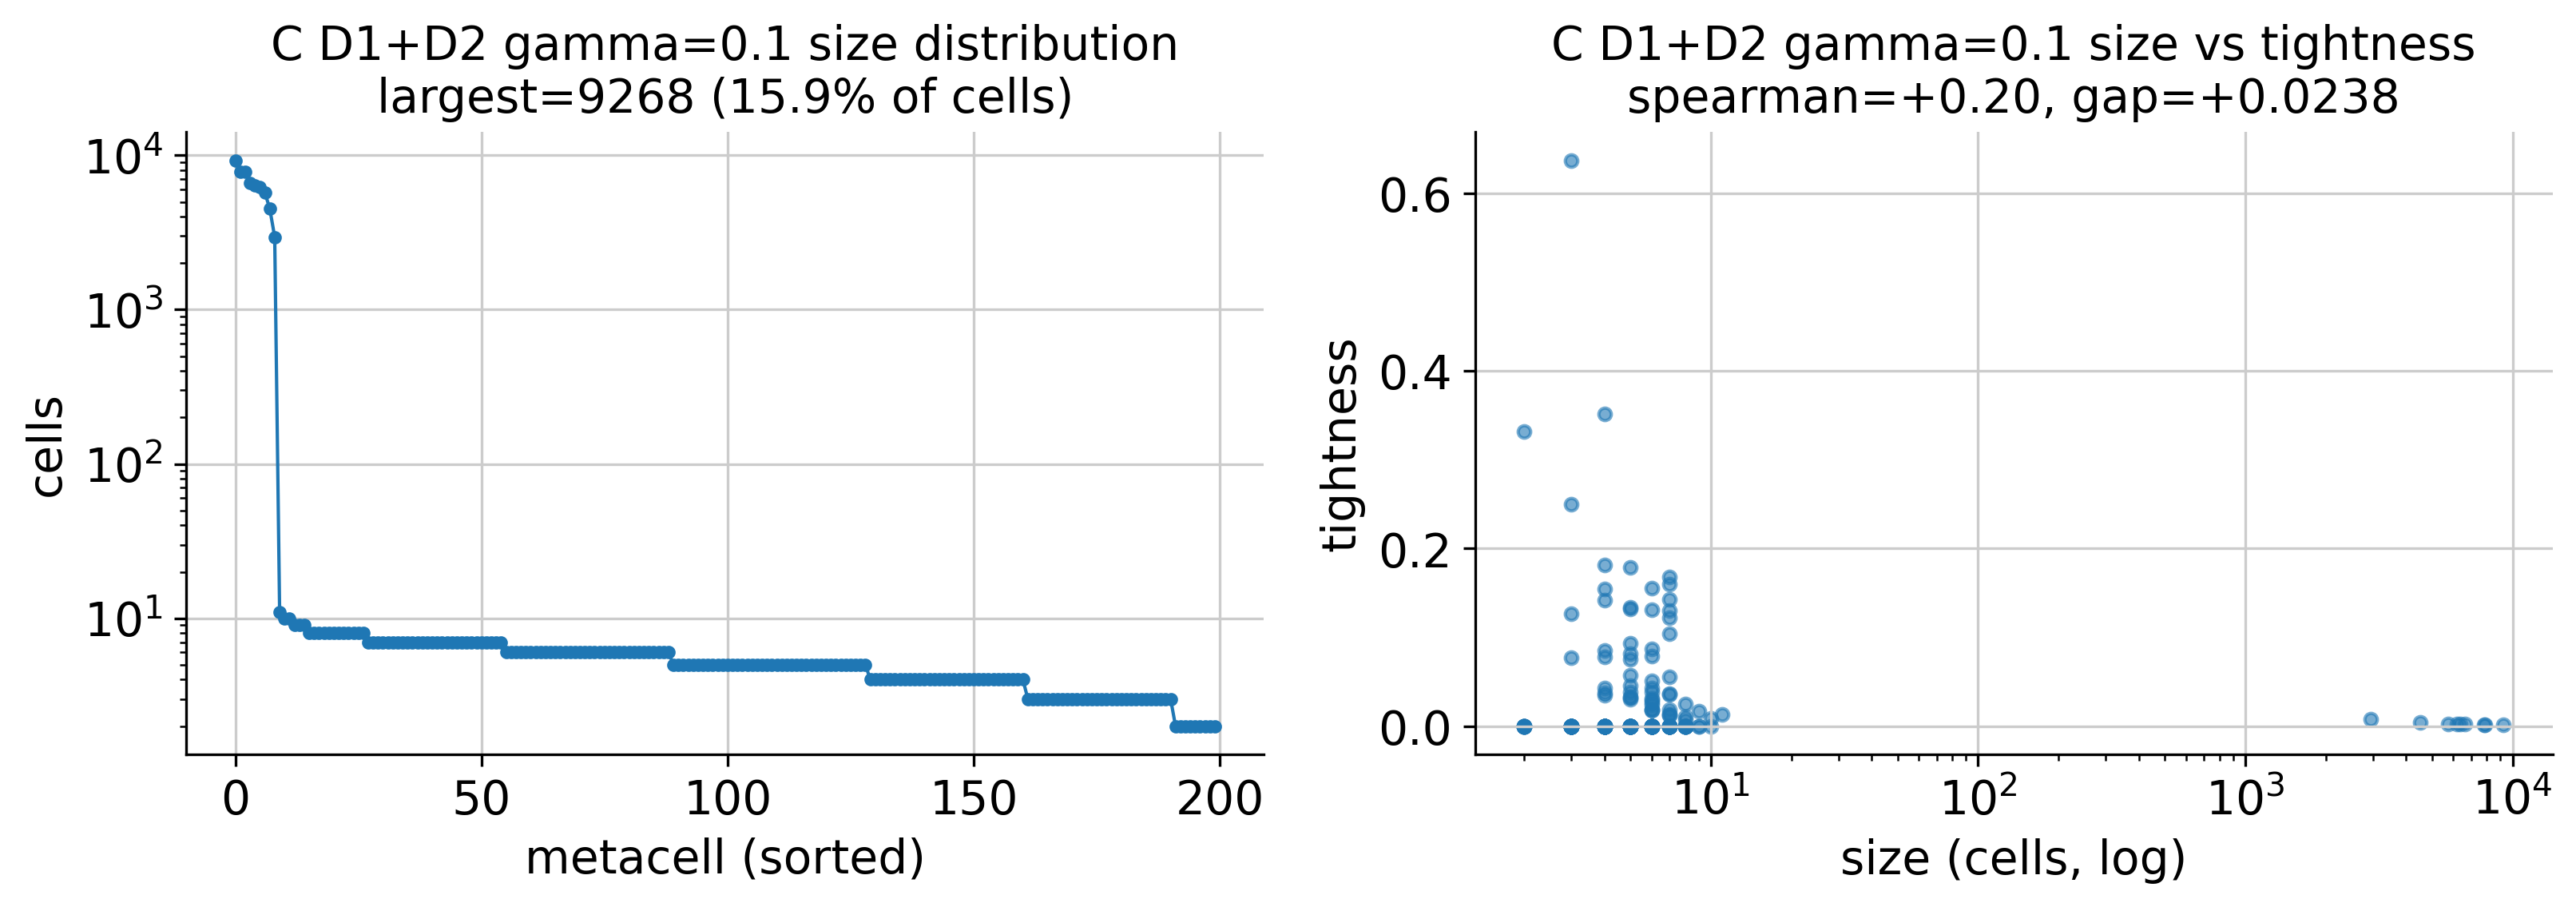

In [ ]:
for g in GAMMAS:
    name = f'C_d1d2_g{g}'
    lcC = dict(LAMBDA_PROTO_UMAP_PRECON)
    lcC['nassoc_diag_norm'] = 'pair'
    lcC['nassoc_diag_loss'] = 'cpm'
    lcC['nassoc_gamma'] = g
    expC = f'proto_bk08_np200_ema15_d1d2_g{g}'

    try:
        if not SKIP_IF_EXISTS:
            raise FileNotFoundError
        tC, _, _ = run_mc_task(
            DS_ID, **{**BASE_KW, 'train_epochs': 1, 'eval_freq': 1, 'patience': 1},
            lambda_config=lcC, trainer_kwargs={'experiment_name': expC},
            load_umap=True, skip_eval=True)
        print(f'loaded existing gamma={g}')
    except FileNotFoundError:
        print(f'=== training D1+D2, gamma={g} ===')
        tC, _, _ = run_mc_task(DS_ID, **BASE_KW, lambda_config=lcC,
                               trainer_kwargs={'experiment_name': expC})
    print('model name:', tC.get_model_name())

    lab = labels_from_trainer(tC, adata)
    labels_by_run[name] = lab
    pur = joint_purity_per_metacell(lab, adata, CT_KEY, NICHE_KEY)
    summaries[name] = collapse_summary(lab, affinity=affinity, name=name, purity=pur)
    # save after EVERY gamma so a disconnect costs one gamma, not the sweep
    pd.DataFrame(list(summaries.values())).set_index('run').to_csv(
        f'{OUT_DIR}/collapse_summary.csv')

    plot_collapse(lab, affinity, name=f'C D1+D2 gamma={g}')
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/{name}.png', dpi=120, bbox_inches='tight')
    plt.show()

    del tC; gc.collect(); torch.cuda.empty_cache()

## Run D -- hinge control, ONE run at the best gamma from the C sweep

Isolates a single question: is it enough to *lift* the target (hinge pays only below
`gamma`, nothing above), or does the `pairs` weighting in `cpm` -- which lets a big loose
prototype dominate the loss -- actually matter? Same `gamma`, same everything else, so the
only difference is floor-vs-reward. Not swept: one run answers it.

In [ ]:
BEST_GAMMA = None    # <-- set from the C sweep above (the gamma with the best size/tightness
                     #     trade-off), then run this cell. None = skip.

if BEST_GAMMA is not None:
    name = f'D_hinge_g{BEST_GAMMA}'
    lcD = dict(LAMBDA_PROTO_UMAP_PRECON)
    lcD['nassoc_diag_norm'] = 'pair'
    lcD['nassoc_diag_loss'] = 'hinge'
    lcD['nassoc_gamma'] = BEST_GAMMA
    expD = f'proto_bk08_np200_ema15_d1hinge_g{BEST_GAMMA}'
    try:
        if not SKIP_IF_EXISTS:
            raise FileNotFoundError
        tD, _, _ = run_mc_task(
            DS_ID, **{**BASE_KW, 'train_epochs': 1, 'eval_freq': 1, 'patience': 1},
            lambda_config=lcD, trainer_kwargs={'experiment_name': expD},
            load_umap=True, skip_eval=True)
        print('loaded existing hinge run')
    except FileNotFoundError:
        print(f'=== training hinge control, gamma={BEST_GAMMA} ===')
        tD, _, _ = run_mc_task(DS_ID, **BASE_KW, lambda_config=lcD,
                               trainer_kwargs={'experiment_name': expD})
    print('model name:', tD.get_model_name())

    lab = labels_from_trainer(tD, adata)
    labels_by_run[name] = lab
    pur = joint_purity_per_metacell(lab, adata, CT_KEY, NICHE_KEY)
    summaries[name] = collapse_summary(lab, affinity=affinity, name=name, purity=pur)
    pd.DataFrame(list(summaries.values())).set_index('run').to_csv(
        f'{OUT_DIR}/collapse_summary.csv')
    plot_collapse(lab, affinity, name=f'D hinge gamma={BEST_GAMMA}')
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/{name}.png', dpi=120, bbox_inches='tight')
    plt.show()
    del tD; gc.collect(); torch.cuda.empty_cache()
else:
    print('BEST_GAMMA not set -- skipping the hinge control. Set it from the C sweep first.')

BEST_GAMMA not set -- skipping the hinge control. Set it from the C sweep first.


## Final comparison

What to read, in order:

- `largest_share`, `dip_p` -- did collapse happen
  (`dip_p` small = the size distribution is two humps with a gap = the cliff)
- `tightness_gap` (macro - micro) -- ~0 healthy; >>0 = the BIG metacells are the loose ones
- `size_tightness_corr` -- expected ~-0.2; < -0.6 means the giants are pathological.
  NaN means fewer than 3 metacells have >= 2 members, which is itself a collapse signal.
- `purity_micro` / `purity_gap` -- joint (cell type | niche).
  `purity_macro` is deliberately NOT reported: it rises with fragmentation (a singleton
  metacell is 100% pure), so it invites exactly the cross-run comparison that misleads.

In [ ]:
report = pd.DataFrame(list(summaries.values())).set_index('run')
cols = ['largest_share', 'dip_stat', 'dip_p',
        'tightness_gap', 'size_tightness_corr',
        'purity_micro', 'purity_gap']
report = report[[c for c in cols if c in report.columns]]
report.to_csv(f'{OUT_DIR}/collapse_summary.csv')
report.round(4).T

run,A_baseline,SEACells_bk08,B_d1_pair,C_d1d2_g0.01,C_d1d2_g0.03,C_d1d2_g0.1
largest_share,0.1535,0.0329,0.0343,0.1681,0.1640,0.1586
dip_stat,0.0825,0.0208,0.0168,0.1055,0.1073,0.0850
dip_p,0.0000,0.8412,0.9856,0.0000,0.0000,0.0000
tightness_gap,0.0570,0.0511,0.0015,0.0270,0.0153,0.0238
size_tightness_corr,0.0854,-0.9858,-0.3019,0.0632,0.2381,0.2013
purity_micro,0.3129,0.3770,0.3535,0.3137,0.3073,0.3132
purity_gap,0.3071,0.0426,-0.0090,0.1380,0.2423,0.1523


## DGE -- niche-program recovery, same runs (s28nsc, K=200)

Extends the collapse-diagnostics comparison above with the niche-DGE recovery metric used
in `spatial_new_loss_dge.ipynb` (same library: `interpretable_ssl/evaluation/niche_dge.py`),
so every arm in `labels_by_run` -- A/B/C and `SEACells_bk08` (and `SEACells_pca` if it
loaded) -- gets scored on whether its metacells recover known niche-vs-rest transcriptional
programs, not just on collapse shape.

**This is an even comparison.** `SEACells_bk08`'s own `metrics.json` on disk has
`"K_target": 200`, matching every scProto arm's `NP200` here -- unlike the `ss28nsc`
notebook's SEACells comparison, K does not need to be checked or re-run.

**Ground truth / pooled-DE cache paths are dataset-scoped on purpose.**
`get_ground_truth` / `pooled_celltype_de` are plain load-if-exists wrappers keyed only by
the path string you pass -- they do not know which dataset produced the file. `ss28nsc` is
a documented subsample of this same section, so reusing its `files/celltype_niches_full.csv`
here would silently score every arm against the wrong cells. Hence the `_s28nsc` suffix
below, distinct from the `ss28nsc` notebook's paths.

In [ ]:
from interpretable_ssl.evaluation import niche_dge as nd

DGE_GT_PATH = os.path.join(os.environ['CODE_DIR'], 'files', 'celltype_niches_full_s28nsc.csv')
DGE_POOLED_PATH = os.path.join(os.environ['CODE_DIR'], 'files', 'celltype_pooled_de_s28nsc.csv')
DGE_REFERENCE = 'B_d1_pair'      # primary new-loss candidate; change if comparing a different arm
DGE_FORCE_RERUN = False          # True only to deliberately recompute ground truth / per-arm DGE

ground_truth = nd.get_ground_truth(
    adata, DGE_GT_PATH, ct_key=CT_KEY, niche_key=NICHE_KEY, force=DGE_FORCE_RERUN,
)
print(f'{len(ground_truth)} (cell type, niche) pairs')

In [ ]:
# Each arm writes its own CSV before the next starts, so a disconnect loses at most one arm.
dge_results = {}
for name, lab in labels_by_run.items():
    dge_results[name] = nd.run_niche_dge(
        name, lab, adata, ground_truth, OUT_DIR,
        ct_key=CT_KEY, niche_key=NICHE_KEY, force=DGE_FORCE_RERUN,
    )
    gc.collect()

In [ ]:
dge_summary = nd.summary_table(dge_results)
dge_summary.to_csv(f'{OUT_DIR}/dge_summary.csv')
dge_summary.round(3)

In [ ]:
fig = nd.plot_dge_summary(
    dge_summary, highlight=DGE_REFERENCE,
    out_path=f'{FIG_DIR}/dge_summary.png',
    title='Niche-program recovery, within cell type (s28nsc, K=200)',
)
plt.show()

### Paired, per (cell type, niche)

`pearson_r_gap_<arm>` = that arm minus `DGE_REFERENCE`. Negative gap = `DGE_REFERENCE` wins
on that pair.

In [ ]:
dge_paired = nd.compare_arms(dge_results, reference=DGE_REFERENCE, metric='pearson_r')
gap_cols = [c for c in dge_paired.columns if c.startswith('pearson_r_gap_')]
if gap_cols:
    dge_paired = dge_paired.sort_values(gap_cols[0], ascending=False)
dge_paired.to_csv(f'{OUT_DIR}/dge_paired.csv', index=False)
dge_paired.round(3).head(25)

### Size-floor sweep -- is a remaining gap a size artifact or missing signal?

Restricts the comparison to pairs where `DGE_REFERENCE`'s own niche-positive metacells
clear a rising size floor. Rising toward the baselines = small-N pseudobulk noise. Flat at
floor 30-50 = the signal genuinely is not there.

In [ ]:
dge_sweep = nd.size_floor_sweep(dge_results, size_arm=DGE_REFERENCE)
dge_sweep.to_csv(f'{OUT_DIR}/dge_size_floor_sweep.csv', index=False)
print(dge_sweep.round(3).to_string(index=False))

In [ ]:
fig = nd.plot_size_floor_sweep(
    dge_sweep, arms=list(dge_results), highlight=DGE_REFERENCE,
    out_path=f'{FIG_DIR}/dge_size_floor_sweep.png',
)
plt.show()